In [1]:
import sys
from pathlib import Path

print("Python version:", sys.version)
print("Python executable:", sys.executable)
print("Working directory:", Path.cwd())

Python version: 3.11.0 (main, Oct 24 2022, 18:26:48) [MSC v.1933 64 bit (AMD64)]
Python executable: C:\Users\admca\Documents\FloodSense_Model_Development\.venv\Scripts\python.exe
Working directory: C:\Users\admca\Documents\FloodSense_Model_Development\notebooks


In [2]:
PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)
print("Source folder exists:", (PROJECT_ROOT / "src").exists())
print("Data folder exists:", (PROJECT_ROOT / "data").exists())

Project root: C:\Users\admca\Documents\FloodSense_Model_Development
Source folder exists: True
Data folder exists: True


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV

from src.config import CLEAN_TRAINING_PATH, SEED, TARGET
from src.models import get_lightgbm
from src.features import (
    get_xy,
    build_preprocessor,
    area_group_splits,
    leave_one_storm_out_splits,
    describe_splits
)
from src.evaluate import cross_validate, compute_metrics

print("All imports successful.")
print("Random seed:", SEED)
print("Target variable:", TARGET)
print("Training dataset:", CLEAN_TRAINING_PATH)

All imports successful.
Random seed: 42
Target variable: flooded
Training dataset: C:\Users\admca\Documents\FloodSense_Model_Development\data\processed\training_clean.csv


In [7]:
df = pd.read_csv(CLEAN_TRAINING_PATH)

DROP_FEATURES = ("rainfall_inches",)

X, y = get_xy(df, drop_features=DROP_FEATURES)

print("Full dataset shape:", df.shape)
print("Input feature shape:", X.shape)
print("Target shape:", y.shape)
print("\nSelected features:")
print(X.columns.tolist())
print("\nTarget distribution:")
print(y.value_counts())

Full dataset shape: (66514, 14)
Input feature shape: (66514, 5)
Target shape: (66514,)

Selected features:
['elevation_m', 'slope_degrees', 'distance_to_bayou_m', 'paved_pct', 'land_cover_type']

Target distribution:
flooded
1    33955
0    32559
Name: count, dtype: int64


In [8]:
area_splits = list(area_group_splits(df, n_splits=5))

print("Number of geographic folds:", len(area_splits))
print()

describe_splits(
    area_splits,
    df,
    allow_overlap=False
)

Number of geographic folds: 5

Split 1: train=53211, validation=13303
  train class counts: {0: 26058, 1: 27153}
  train class proportions: {0: 0.49, 1: 0.51}
  validation class counts: {0: 6501, 1: 6802}
  validation class proportions: {0: 0.489, 1: 0.511}
  grid_id overlap: none
Split 2: train=53211, validation=13303
  train class counts: {0: 26041, 1: 27170}
  train class proportions: {0: 0.489, 1: 0.511}
  validation class counts: {0: 6518, 1: 6785}
  validation class proportions: {0: 0.49, 1: 0.51}
  grid_id overlap: none
Split 3: train=53211, validation=13303
  train class counts: {0: 26013, 1: 27198}
  train class proportions: {0: 0.489, 1: 0.511}
  validation class counts: {0: 6546, 1: 6757}
  validation class proportions: {0: 0.492, 1: 0.508}
  grid_id overlap: none
Split 4: train=53211, validation=13303
  train class counts: {0: 26049, 1: 27162}
  train class proportions: {0: 0.49, 1: 0.51}
  validation class counts: {0: 6510, 1: 6793}
  validation class proportions: {0: 0.48

In [9]:
storm_splits = list(
    leave_one_storm_out_splits(
        df,
        drop_overlap_areas=False
    )
)

print("Number of storm folds:", len(storm_splits))
print()

describe_splits(
    storm_splits,
    df,
    allow_overlap=True
)

Number of storm folds: 3

Storm Memorial Day Flood: train=44734, validation=21780
  train class counts: {0: 21777, 1: 22957}
  train class proportions: {0: 0.487, 1: 0.513}
  validation class counts: {0: 10782, 1: 10998}
  validation class proportions: {0: 0.495, 1: 0.505}
  validation grid_ids also in training: 3881/3997 (97.1%)
Storm Tax Day Flood: train=44664, validation=21850
  train class counts: {0: 21833, 1: 22831}
  train class proportions: {0: 0.489, 1: 0.511}
  validation class counts: {0: 10726, 1: 11124}
  validation class proportions: {0: 0.491, 1: 0.509}
  validation grid_ids also in training: 3892/4000 (97.3%)
Storm Hurricane Harvey: train=43630, validation=22884
  train class counts: {0: 21508, 1: 22122}
  train class proportions: {0: 0.493, 1: 0.507}
  validation class counts: {0: 11051, 1: 11833}
  validation class proportions: {0: 0.483, 1: 0.517}
  validation grid_ids also in training: 3907/4022 (97.1%)


In [10]:
baseline_area_summary, baseline_area_oof = cross_validate(
    model_factory=get_lightgbm,
    df=df,
    splits=area_splits,
    name="lightgbm",
    split_name="area",
    drop_features=DROP_FEATURES
)

display(baseline_area_summary)

,model,split,fold,accuracy,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp
0,lightgbm,area,1,0.814553,0.806014,0.839312,0.822326,0.892127,0.870334,5127.000000,1374.000000,1093.000000,5709.000000
1,lightgbm,area,2,0.813050,0.797316,0.849374,0.822522,0.890831,0.866554,5053.000000,1465.000000,1022.000000,5763.000000
2,lightgbm,area,3,0.811396,0.796731,0.844014,0.819691,0.888378,0.865616,5091.000000,1455.000000,1054.000000,5703.000000
3,lightgbm,area,4,0.821018,0.798997,0.867805,0.831981,0.892043,0.866532,5027.000000,1483.000000,898.000000,5895.000000
4,lightgbm,area,5,0.824011,0.806854,0.863303,0.834125,0.893056,0.869675,5075.000000,1409.000000,932.000000,5886.000000
5,lightgbm,area,mean,0.816806,0.801182,0.852761,0.826129,0.891287,0.867742,5074.600000,1437.200000,999.800000,5791.200000
6,lightgbm,area,std,0.005434,0.004875,0.012312,0.006463,0.001808,0.002112,37.905145,44.656466,82.275148,93.665362


In [11]:
baseline_storm_summary, baseline_storm_oof = cross_validate(
    model_factory=get_lightgbm,
    df=df,
    splits=storm_splits,
    name="lightgbm",
    split_name="storm",
    drop_features=DROP_FEATURES
)

display(baseline_storm_summary)

,model,split,fold,accuracy,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp
0,lightgbm,storm,1,0.836134,0.802706,0.895617,0.846620,0.906751,0.882489,8361.000000,2421.000000,1148.000000,9850.000000
1,lightgbm,storm,2,0.828650,0.803454,0.878281,0.839203,0.898621,0.874319,8336.000000,2390.000000,1354.000000,9770.000000
2,lightgbm,storm,3,0.830187,0.809102,0.878983,0.842596,0.899057,0.874767,8597.000000,2454.000000,1432.000000,10401.000000
3,lightgbm,storm,mean,0.831657,0.805087,0.884294,0.842806,0.901477,0.877192,8431.333333,2421.666667,1311.333333,10007.000000
4,lightgbm,storm,std,0.003953,0.003497,0.009813,0.003713,0.004573,0.004593,144.015046,32.005208,146.728775,343.550579


In [12]:
param_distributions = {
    "model__n_estimators": [100, 200, 300, 500],
    "model__learning_rate": [0.01, 0.05, 0.1],
    "model__num_leaves": [15, 31, 63],
    "model__max_depth": [5, 10, -1],
    "model__min_child_samples": [20, 50, 100],
    "model__reg_alpha": [0, 0.1, 1],
    "model__reg_lambda": [0, 0.1, 1]
}

total_combinations = 1

for parameter, values in param_distributions.items():
    total_combinations *= len(values)
    print(parameter, ":", values)

print("\nTotal possible combinations:", total_combinations)

model__n_estimators : [100, 200, 300, 500]
model__learning_rate : [0.01, 0.05, 0.1]
model__num_leaves : [15, 31, 63]
model__max_depth : [5, 10, -1]
model__min_child_samples : [20, 50, 100]
model__reg_alpha : [0, 0.1, 1]
model__reg_lambda : [0, 0.1, 1]

Total possible combinations: 2916


In [13]:
N_ITER = 20
SCORING = "roc_auc"
SEARCH_SEED = SEED

AREA_INNER_FOLDS = 4
STORM_INNER_FOLDS = 2

print("Search method: RandomizedSearchCV")
print("Combinations per search:", N_ITER)
print("Optimization metric:", SCORING)
print("Random seed:", SEARCH_SEED)
print("Geographic inner folds:", AREA_INNER_FOLDS)
print("Storm inner folds:", STORM_INNER_FOLDS)

print("\nPercentage of search space sampled per search:",
      round(N_ITER / total_combinations * 100, 2), "%")

Search method: RandomizedSearchCV
Combinations per search: 20
Optimization metric: roc_auc
Random seed: 42
Geographic inner folds: 4
Storm inner folds: 2

Percentage of search space sampled per search: 0.69 %


In [14]:
outer_train_idx, outer_val_idx = area_splits[0]

outer_train_df = df.iloc[outer_train_idx].reset_index(drop=True)
outer_val_df = df.iloc[outer_val_idx].reset_index(drop=True)

inner_area_splits = list(
    area_group_splits(
        outer_train_df,
        n_splits=AREA_INNER_FOLDS
    )
)

print("Outer training shape:", outer_train_df.shape)
print("Outer validation shape:", outer_val_df.shape)
print("Number of inner folds:", len(inner_area_splits))
print()

describe_splits(
    inner_area_splits,
    outer_train_df,
    allow_overlap=False
)

Outer training shape: (53211, 14)
Outer validation shape: (13303, 14)
Number of inner folds: 4

Split 1: train=39908, validation=13303
  train class counts: {0: 19540, 1: 20368}
  train class proportions: {0: 0.49, 1: 0.51}
  validation class counts: {0: 6518, 1: 6785}
  validation class proportions: {0: 0.49, 1: 0.51}
  grid_id overlap: none
Split 2: train=39908, validation=13303
  train class counts: {0: 19512, 1: 20396}
  train class proportions: {0: 0.489, 1: 0.511}
  validation class counts: {0: 6546, 1: 6757}
  validation class proportions: {0: 0.492, 1: 0.508}
  grid_id overlap: none
Split 3: train=39908, validation=13303
  train class counts: {0: 19548, 1: 20360}
  train class proportions: {0: 0.49, 1: 0.51}
  validation class counts: {0: 6510, 1: 6793}
  validation class proportions: {0: 0.489, 1: 0.511}
  grid_id overlap: none
Split 4: train=39909, validation=13302
  train class counts: {0: 19574, 1: 20335}
  train class proportions: {0: 0.49, 1: 0.51}
  validation class coun

In [15]:
outer_storm_name, outer_storm_train_idx, outer_storm_val_idx = storm_splits[0]

outer_storm_train_df = df.iloc[outer_storm_train_idx].reset_index(drop=True)
outer_storm_val_df = df.iloc[outer_storm_val_idx].reset_index(drop=True)

inner_storm_splits = list(
    leave_one_storm_out_splits(
        outer_storm_train_df,
        drop_overlap_areas=False
    )
)

print("Outer held-out storm:", outer_storm_name)
print("Outer training shape:", outer_storm_train_df.shape)
print("Outer validation shape:", outer_storm_val_df.shape)
print("Number of inner folds:", len(inner_storm_splits))

print("\nStorms available for hyperparameter selection:")
print(outer_storm_train_df["storm_name"].value_counts())
print()

describe_splits(
    inner_storm_splits,
    outer_storm_train_df,
    allow_overlap=True
)

Outer held-out storm: Memorial Day Flood
Outer training shape: (44734, 14)
Outer validation shape: (21780, 14)
Number of inner folds: 2

Storms available for hyperparameter selection:
storm_name
Hurricane Harvey    22884
Tax Day Flood       21850
Name: count, dtype: int64

Storm Tax Day Flood: train=22884, validation=21850
  train class counts: {0: 11051, 1: 11833}
  train class proportions: {0: 0.483, 1: 0.517}
  validation class counts: {0: 10726, 1: 11124}
  validation class proportions: {0: 0.491, 1: 0.509}
  validation grid_ids also in training: 3646/4000 (91.2%)
Storm Hurricane Harvey: train=21850, validation=22884
  train class counts: {0: 10726, 1: 11124}
  train class proportions: {0: 0.491, 1: 0.509}
  validation class counts: {0: 11051, 1: 11833}
  validation class proportions: {0: 0.483, 1: 0.517}
  validation grid_ids also in training: 3646/4022 (90.7%)


In [16]:
def build_tuning_pipeline():
    return Pipeline([
        (
            "preprocessor",
            build_preprocessor(drop_features=DROP_FEATURES)
        ),
        (
            "model",
            get_lightgbm()
        )
    ])

tuning_pipeline = build_tuning_pipeline()

print("Pipeline steps:")
print(list(tuning_pipeline.named_steps.keys()))

print("\nHyperparameter names are valid:")
for parameter in param_distributions:
    print(parameter, ":", parameter in tuning_pipeline.get_params())

Pipeline steps:
['preprocessor', 'model']

Hyperparameter names are valid:
model__n_estimators : True
model__learning_rate : True
model__num_leaves : True
model__max_depth : True
model__min_child_samples : True
model__reg_alpha : True
model__reg_lambda : True


In [17]:
def build_randomized_search(inner_splits):
    search = RandomizedSearchCV(
        estimator=build_tuning_pipeline(),
        param_distributions=param_distributions,
        n_iter=N_ITER,
        scoring=SCORING,
        cv=inner_splits,
        random_state=SEARCH_SEED,
        n_jobs=1,
        refit=True,
        return_train_score=True,
        verbose=1,
        error_score="raise"
    )

    return search

area_search = build_randomized_search(inner_area_splits)

print("Search configuration:")
print("Number of combinations:", area_search.n_iter)
print("Scoring metric:", area_search.scoring)
print("Number of inner folds:", len(area_search.cv))
print("Random seed:", area_search.random_state)
print("Refit best model:", area_search.refit)

print("\nTotal candidate evaluation fits:",
      area_search.n_iter * len(area_search.cv))

Search configuration:
Number of combinations: 20
Scoring metric: roc_auc
Number of inner folds: 4
Random seed: 42
Refit best model: True

Total candidate evaluation fits: 80


In [18]:
import time

X_outer_train, y_outer_train = get_xy(
    outer_train_df,
    drop_features=DROP_FEATURES
)

print("Training feature shape:", X_outer_train.shape)
print("Training target shape:", y_outer_train.shape)
print("\nStarting randomized search...\n")

start_time = time.perf_counter()

area_search.fit(X_outer_train, y_outer_train)

elapsed_time = time.perf_counter() - start_time

print("\nSearch completed.")
print("Elapsed time (seconds):", round(elapsed_time, 2))
print("Elapsed time (minutes):", round(elapsed_time / 60, 2))

print("\nBest inner validation ROC-AUC:", area_search.best_score_)

print("\nBest hyperparameters:")
for parameter, value in area_search.best_params_.items():
    print(parameter, ":", value)

Training feature shape: (53211, 5)
Training target shape: (53211,)

Starting randomized search...

Fitting 4 folds for each of 20 candidates, totalling 80 fits

Search completed.
Elapsed time (seconds): 96.51
Elapsed time (minutes): 1.61

Best inner validation ROC-AUC: 0.8837878296350903

Best hyperparameters:
model__reg_lambda : 1
model__reg_alpha : 0
model__num_leaves : 15
model__n_estimators : 500
model__min_child_samples : 50
model__max_depth : 5
model__learning_rate : 0.1


In [19]:
area_search_results = pd.DataFrame(area_search.cv_results_)

area_search_results["train_validation_gap"] = (
    area_search_results["mean_train_score"]
    - area_search_results["mean_test_score"]
)

top_area_results = area_search_results.sort_values(
    "rank_test_score"
).head(5)

display(top_area_results[[
    "rank_test_score",
    "mean_train_score",
    "mean_test_score",
    "std_test_score",
    "train_validation_gap",
    "mean_fit_time",
    "params"
]])

,rank_test_score,mean_train_score,mean_test_score,std_test_score,train_validation_gap,mean_fit_time,params
10,1,0.924803,0.883788,0.002854,0.041015,0.762919,"{'model__reg_lambda': 1, 'model__reg_alpha': 0..."
9,2,0.934770,0.883783,0.002229,0.050987,1.191035,"{'model__reg_lambda': 0, 'model__reg_alpha': 1..."
12,3,0.920102,0.883400,0.003200,0.036701,0.993573,"{'model__reg_lambda': 1, 'model__reg_alpha': 0..."
17,4,0.917852,0.882897,0.002651,0.034955,0.690048,"{'model__reg_lambda': 0, 'model__reg_alpha': 0..."
1,5,0.914911,0.882067,0.002963,0.032844,1.246719,"{'model__reg_lambda': 0.1, 'model__reg_alpha':..."


In [23]:
X_outer_val, y_outer_val = get_xy(
    outer_val_df,
    drop_features=DROP_FEATURES
)

best_area_model = area_search.best_estimator_

tuned_area_prob = best_area_model.predict_proba(
    X_outer_val
)[:, 1]

tuned_area_metrics = compute_metrics(
    y_outer_val,
    tuned_area_prob,
    threshold=0.5
)

print("First tuned geographic fold results:\n")

for metric, value in tuned_area_metrics.items():
    print(metric, ":", round(value, 6))

First tuned geographic fold results:

accuracy : 0.811471
precision : 0.803334
recall : 0.835931
f1 : 0.819308
roc_auc : 0.889305
pr_auc : 0.869004
tn : 5109
fp : 1392
fn : 1116
tp : 5686


In [24]:
tuned_area_records = [{
    "fold": 1,
    "best_inner_roc_auc": area_search.best_score_,
    "runtime_seconds": elapsed_time,
    **tuned_area_metrics
}]

tuned_area_params = [{
    "fold": 1,
    **area_search.best_params_
}]

tuned_area_oof_records = [
    pd.DataFrame({
        "row_index": outer_val_idx,
        "y_true": y_outer_val.to_numpy(),
        "y_prob": tuned_area_prob,
        "fold": 1
    })
]

print("Stored metric records:", len(tuned_area_records))
print("Stored hyperparameter records:", len(tuned_area_params))
print("Stored prediction records:", len(tuned_area_oof_records))
print("Stored validation predictions:",
      len(tuned_area_oof_records[0]))

display(pd.DataFrame(tuned_area_records))

Stored metric records: 1
Stored hyperparameter records: 1
Stored prediction records: 1
Stored validation predictions: 13303


,fold,best_inner_roc_auc,runtime_seconds,accuracy,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp
0,1,0.883788,96.506604,0.811471,0.803334,0.835931,0.819308,0.889305,0.869004,5109,1392,1116,5686


In [25]:
for fold_number, (train_idx, val_idx) in enumerate(
    area_splits, start=1
):
    # Skip previously completed folds
    if any(
        record["fold"] == fold_number
        for record in tuned_area_records
    ):
        continue

    print(f"\n{'=' * 50}")
    print(f"Geographic outer fold {fold_number}")
    print(f"{'=' * 50}")

    # Create outer training and validation datasets
    train_df = df.iloc[train_idx].reset_index(drop=True)
    val_df = df.iloc[val_idx].reset_index(drop=True)

    # Create inner geographic splits
    inner_splits = list(
        area_group_splits(
            train_df,
            n_splits=AREA_INNER_FOLDS
        )
    )

    # Extract features and labels
    X_train, y_train = get_xy(
        train_df,
        drop_features=DROP_FEATURES
    )

    X_val, y_val = get_xy(
        val_df,
        drop_features=DROP_FEATURES
    )

    # Configure and execute randomized search
    search = build_randomized_search(inner_splits)

    start_time = time.perf_counter()

    search.fit(X_train, y_train)

    runtime = time.perf_counter() - start_time

    # Evaluate the best model
    best_model = search.best_estimator_

    y_prob = best_model.predict_proba(X_val)[:, 1]

    metrics = compute_metrics(
        y_val,
        y_prob,
        threshold=0.5
    )

    # Store evaluation metrics
    tuned_area_records.append({
        "fold": fold_number,
        "best_inner_roc_auc": search.best_score_,
        "runtime_seconds": runtime,
        **metrics
    })

    # Store selected hyperparameters
    tuned_area_params.append({
        "fold": fold_number,
        **search.best_params_
    })

    # Store validation predictions
    tuned_area_oof_records.append(
        pd.DataFrame({
            "row_index": val_idx,
            "y_true": y_val.to_numpy(),
            "y_prob": y_prob,
            "fold": fold_number
        })
    )

    # Display fold results
    print("\nBest inner ROC-AUC:",
          round(search.best_score_, 6))
    print("Outer ROC-AUC:",
          round(metrics["roc_auc"], 6))
    print("Outer accuracy:",
          round(metrics["accuracy"], 6))
    print("Outer recall:",
          round(metrics["recall"], 6))
    print("Runtime (seconds):", round(runtime, 2))

print("\nAll geographic folds completed.")


Geographic outer fold 2
Fitting 4 folds for each of 20 candidates, totalling 80 fits

Best inner ROC-AUC: 0.883882
Outer ROC-AUC: 0.891178
Outer accuracy: 0.811546
Outer recall: 0.847605
Runtime (seconds): 86.21

Geographic outer fold 3
Fitting 4 folds for each of 20 candidates, totalling 80 fits

Best inner ROC-AUC: 0.885546
Outer ROC-AUC: 0.887062
Outer accuracy: 0.810945
Outer recall: 0.846086
Runtime (seconds): 81.11

Geographic outer fold 4
Fitting 4 folds for each of 20 candidates, totalling 80 fits

Best inner ROC-AUC: 0.8823
Outer ROC-AUC: 0.885695
Outer accuracy: 0.812824
Outer recall: 0.859709
Runtime (seconds): 272.76

Geographic outer fold 5
Fitting 4 folds for each of 20 candidates, totalling 80 fits

Best inner ROC-AUC: 0.881928
Outer ROC-AUC: 0.891934
Outer accuracy: 0.819877
Outer recall: 0.86081
Runtime (seconds): 83.65

All geographic folds completed.


In [26]:
tuned_area_results = pd.DataFrame(tuned_area_records)

performance_metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc",
    "pr_auc"
]

tuned_area_summary = tuned_area_results[
    performance_metrics
].agg(["mean", "std"])

print("Tuned geographic fold results:")
display(tuned_area_results)

print("\nTuned geographic summary:")
display(tuned_area_summary)

print("\nTotal runtime (minutes):",
      round(tuned_area_results["runtime_seconds"].sum() / 60, 2))

Tuned geographic fold results:


,fold,best_inner_roc_auc,runtime_seconds,accuracy,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp
0,1,0.883788,96.506604,0.811471,0.803334,0.835931,0.819308,0.889305,0.869004,5109,1392,1116,5686
1,2,0.883882,86.207107,0.811546,0.796096,0.847605,0.821044,0.891178,0.866917,5045,1473,1034,5751
2,3,0.885546,81.107445,0.810945,0.794911,0.846086,0.819700,0.887062,0.864939,5071,1475,1040,5717
3,4,0.882300,272.760614,0.812824,0.791650,0.859709,0.824277,0.885695,0.860590,4973,1537,953,5840
4,5,0.881928,83.654890,0.819877,0.802214,0.860810,0.830480,0.891934,0.868402,5037,1447,949,5869



Tuned geographic summary:


,accuracy,precision,recall,f1,roc_auc,pr_auc
mean,0.813333,0.797641,0.850028,0.822962,0.889035,0.865970
std,0.003723,0.004977,0.010370,0.004634,0.002651,0.003392



Total runtime (minutes): 10.34


In [30]:
baseline_area_indexed = baseline_area_summary.set_index("fold")

baseline_area_mean = baseline_area_indexed.loc[
    "mean", performance_metrics
]

baseline_area_std = baseline_area_indexed.loc[
    "std", performance_metrics
]

area_comparison = pd.DataFrame({
    "baseline_mean": baseline_area_mean,
    "tuned_mean": tuned_area_summary.loc["mean"],
    "baseline_std": baseline_area_std,
    "tuned_std": tuned_area_summary.loc["std"]
})

area_comparison["mean_difference"] = (
    area_comparison["tuned_mean"]
    - area_comparison["baseline_mean"]
)

area_comparison["std_difference"] = (
    area_comparison["tuned_std"]
    - area_comparison["baseline_std"]
)

print("Geographic baseline vs. tuned comparison:")

display(area_comparison.round(6))

Geographic baseline vs. tuned comparison:


,baseline_mean,tuned_mean,baseline_std,tuned_std,mean_difference,std_difference
accuracy,0.816806,0.813333,0.005434,0.003723,-0.003473,-0.001711
precision,0.801182,0.797641,0.004875,0.004977,-0.003541,0.000102
recall,0.852761,0.850028,0.012312,0.010370,-0.002734,-0.001942
f1,0.826129,0.822962,0.006463,0.004634,-0.003167,-0.001829
roc_auc,0.891287,0.889035,0.001808,0.002651,-0.002252,0.000843
pr_auc,0.867742,0.865970,0.002112,0.003392,-0.001772,0.001279


In [31]:
inner_storm_cv = [
    (train_idx, val_idx)
    for storm_name, train_idx, val_idx
    in inner_storm_splits
]

print("Outer validation storm:", outer_storm_name)
print("Number of inner folds:", len(inner_storm_cv))

for fold_number, (train_idx, val_idx) in enumerate(
    inner_storm_cv, start=1
):
    print(f"\nInner fold {fold_number}")
    print("Training observations:", len(train_idx))
    print("Validation observations:", len(val_idx))

storm_search = build_randomized_search(inner_storm_cv)

print("\nStorm search configuration:")
print("Number of combinations:", storm_search.n_iter)
print("Scoring metric:", storm_search.scoring)
print("Number of inner folds:", len(storm_search.cv))

print("\nTotal candidate evaluation fits:",
      storm_search.n_iter * len(storm_search.cv))

Outer validation storm: Memorial Day Flood
Number of inner folds: 2

Inner fold 1
Training observations: 22884
Validation observations: 21850

Inner fold 2
Training observations: 21850
Validation observations: 22884

Storm search configuration:
Number of combinations: 20
Scoring metric: roc_auc
Number of inner folds: 2

Total candidate evaluation fits: 40


In [32]:
X_storm_train, y_storm_train = get_xy(
    outer_storm_train_df,
    drop_features=DROP_FEATURES
)

print("Outer validation storm:", outer_storm_name)
print("Training feature shape:", X_storm_train.shape)
print("Training target shape:", y_storm_train.shape)
print("\nStarting randomized storm search...\n")

storm_start_time = time.perf_counter()

storm_search.fit(X_storm_train, y_storm_train)

storm_elapsed_time = time.perf_counter() - storm_start_time

print("\nSearch completed.")
print("Elapsed time (seconds):",
      round(storm_elapsed_time, 2))
print("Elapsed time (minutes):",
      round(storm_elapsed_time / 60, 2))

print("\nBest inner validation ROC-AUC:",
      storm_search.best_score_)

print("\nBest hyperparameters:")
for parameter, value in storm_search.best_params_.items():
    print(parameter, ":", value)

Outer validation storm: Memorial Day Flood
Training feature shape: (44734, 5)
Training target shape: (44734,)

Starting randomized storm search...

Fitting 2 folds for each of 20 candidates, totalling 40 fits

Search completed.
Elapsed time (seconds): 38.06
Elapsed time (minutes): 0.63

Best inner validation ROC-AUC: 0.8888612768953581

Best hyperparameters:
model__reg_lambda : 1
model__reg_alpha : 0
model__num_leaves : 15
model__n_estimators : 500
model__min_child_samples : 50
model__max_depth : 5
model__learning_rate : 0.1


In [33]:
X_storm_val, y_storm_val = get_xy(
    outer_storm_val_df,
    drop_features=DROP_FEATURES
)

best_storm_model = storm_search.best_estimator_

tuned_storm_prob = best_storm_model.predict_proba(
    X_storm_val
)[:, 1]

tuned_storm_metrics = compute_metrics(
    y_storm_val,
    tuned_storm_prob,
    threshold=0.5
)

print("Outer validation storm:", outer_storm_name)
print("Validation feature shape:", X_storm_val.shape)
print("Number of predictions:", len(tuned_storm_prob))

print("\nTuned storm model performance:")

display(pd.DataFrame([tuned_storm_metrics]).round(6))

Outer validation storm: Memorial Day Flood
Validation feature shape: (21780, 5)
Number of predictions: 21780

Tuned storm model performance:


,accuracy,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp
0,0.82966,0.796743,0.889616,0.840622,0.902793,0.879339,8286,2496,1214,9784


In [34]:
tuned_storm_records = [
    {
        "fold": 1,
        "storm": outer_storm_name,
        "best_inner_roc_auc": storm_search.best_score_,
        "runtime_seconds": storm_elapsed_time,
        **tuned_storm_metrics
    }
]

tuned_storm_params = [
    {
        "fold": 1,
        "storm": outer_storm_name,
        **storm_search.best_params_
    }
]

tuned_storm_oof_records = [
    pd.DataFrame({
        "row_index": outer_storm_val_idx,
        "y_true": y_storm_val.to_numpy(),
        "y_prob": tuned_storm_prob,
        "fold": 1,
        "storm": outer_storm_name
    })
]

print("Stored performance records:",
      len(tuned_storm_records))

print("Stored hyperparameter records:",
      len(tuned_storm_params))

print("Stored OOF DataFrames:",
      len(tuned_storm_oof_records))

print("Stored OOF predictions:",
      len(tuned_storm_oof_records[0]))

print("\nStored validation storm:",
      tuned_storm_records[0]["storm"])

Stored performance records: 1
Stored hyperparameter records: 1
Stored OOF DataFrames: 1
Stored OOF predictions: 21780

Stored validation storm: Memorial Day Flood


In [35]:
for fold_number, (storm_name, train_idx, val_idx) in enumerate(
    storm_splits, start=1
):
    # Skip completed folds
    if any(
        record["fold"] == fold_number
        for record in tuned_storm_records
    ):
        continue

    print(f"\nStarting storm fold {fold_number}")
    print("Validation storm:", storm_name)

    # Prepare outer training and validation datasets
    train_df = df.iloc[train_idx].reset_index(drop=True)
    val_df = df.iloc[val_idx].reset_index(drop=True)

    # Generate inner storm splits
    inner_named_splits = list(
        leave_one_storm_out_splits(
            train_df,
            drop_overlap_areas=False
        )
    )

    # Remove storm names for RandomizedSearchCV
    inner_splits = [
        (inner_train_idx, inner_val_idx)
        for _, inner_train_idx, inner_val_idx
        in inner_named_splits
    ]

    # Extract features and targets
    X_train, y_train = get_xy(
        train_df, drop_features=DROP_FEATURES
    )

    X_val, y_val = get_xy(
        val_df, drop_features=DROP_FEATURES
    )

    # Perform hyperparameter search
    search = build_randomized_search(inner_splits)

    start_time = time.perf_counter()
    search.fit(X_train, y_train)
    runtime = time.perf_counter() - start_time

    # Evaluate the selected model
    best_model = search.best_estimator_
    y_prob = best_model.predict_proba(X_val)[:, 1]

    metrics = compute_metrics(
        y_val, y_prob, threshold=0.5
    )

    # Store performance metrics
    tuned_storm_records.append({
        "fold": fold_number,
        "storm": storm_name,
        "best_inner_roc_auc": search.best_score_,
        "runtime_seconds": runtime,
        **metrics
    })

    # Store selected hyperparameters
    tuned_storm_params.append({
        "fold": fold_number,
        "storm": storm_name,
        **search.best_params_
    })

    # Store out-of-fold predictions
    tuned_storm_oof_records.append(
        pd.DataFrame({
            "row_index": val_idx,
            "y_true": y_val.to_numpy(),
            "y_prob": y_prob,
            "fold": fold_number,
            "storm": storm_name
        })
    )

    # Display fold results
    print(f"\nStorm fold {fold_number} completed.")
    print("Best inner ROC-AUC:", round(search.best_score_, 6))
    print("Outer ROC-AUC:", round(metrics["roc_auc"], 6))
    print("Accuracy:", round(metrics["accuracy"], 6))
    print("Recall:", round(metrics["recall"], 6))
    print("Runtime (seconds):", round(runtime, 2))

print("\nAll storm folds completed.")


Starting storm fold 2
Validation storm: Tax Day Flood
Fitting 2 folds for each of 20 candidates, totalling 40 fits

Storm fold 2 completed.
Best inner ROC-AUC: 0.891472
Outer ROC-AUC: 0.892535
Accuracy: 0.820641
Recall: 0.869022
Runtime (seconds): 29.41

Starting storm fold 3
Validation storm: Hurricane Harvey
Fitting 2 folds for each of 20 candidates, totalling 40 fits

Storm fold 3 completed.
Best inner ROC-AUC: 0.893441
Outer ROC-AUC: 0.898686
Accuracy: 0.829619
Recall: 0.874419
Runtime (seconds): 24.34

All storm folds completed.


In [36]:
tuned_storm_results = pd.DataFrame(tuned_storm_records)

tuned_storm_summary = tuned_storm_results[
    performance_metrics
].agg(["mean", "std"])

print("Tuned storm fold results:")
display(tuned_storm_results)

print("\nTuned storm summary:")
display(tuned_storm_summary)

print("\nTotal runtime (minutes):",
      round(tuned_storm_results["runtime_seconds"].sum() / 60, 2))

Tuned storm fold results:


,fold,storm,best_inner_roc_auc,runtime_seconds,accuracy,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp
0,1,Memorial Day Flood,0.888861,38.058395,0.829660,0.796743,0.889616,0.840622,0.902793,0.879339,8286,2496,1214,9784
1,2,Tax Day Flood,0.891472,29.411389,0.820641,0.797015,0.869022,0.831463,0.892535,0.868493,8264,2462,1457,9667
2,3,Hurricane Harvey,0.893441,24.337510,0.829619,0.810893,0.874419,0.841459,0.898686,0.876116,8638,2413,1486,10347



Tuned storm summary:


,accuracy,precision,recall,f1,roc_auc,pr_auc
mean,0.826640,0.801551,0.877686,0.837848,0.898005,0.87465
std,0.005196,0.008092,0.010679,0.005546,0.005163,0.00557



Total runtime (minutes): 1.53


In [37]:
baseline_storm_indexed = baseline_storm_summary.set_index("fold")

baseline_storm_mean = baseline_storm_indexed.loc[
    "mean", performance_metrics
]

baseline_storm_std = baseline_storm_indexed.loc[
    "std", performance_metrics
]

storm_comparison = pd.DataFrame({
    "baseline_mean": baseline_storm_mean,
    "tuned_mean": tuned_storm_summary.loc["mean"],
    "baseline_std": baseline_storm_std,
    "tuned_std": tuned_storm_summary.loc["std"]
})

storm_comparison["mean_difference"] = (
    storm_comparison["tuned_mean"]
    - storm_comparison["baseline_mean"]
)

storm_comparison["std_difference"] = (
    storm_comparison["tuned_std"]
    - storm_comparison["baseline_std"]
)

print("Storm baseline vs. tuned comparison:")

display(storm_comparison.round(6))

Storm baseline vs. tuned comparison:


,baseline_mean,tuned_mean,baseline_std,tuned_std,mean_difference,std_difference
accuracy,0.831657,0.826640,0.003953,0.005196,-0.005017,0.001243
precision,0.805087,0.801551,0.003497,0.008092,-0.003537,0.004596
recall,0.884294,0.877686,0.009813,0.010679,-0.006608,0.000866
f1,0.842806,0.837848,0.003713,0.005546,-0.004958,0.001833
roc_auc,0.901477,0.898005,0.004573,0.005163,-0.003472,0.000590
pr_auc,0.877192,0.874650,0.004593,0.005570,-0.002542,0.000976


In [38]:
overall_comparison = pd.DataFrame({
    "baseline_area": area_comparison["baseline_mean"],
    "tuned_area": area_comparison["tuned_mean"],
    "area_difference": area_comparison["mean_difference"],
    "baseline_storm": storm_comparison["baseline_mean"],
    "tuned_storm": storm_comparison["tuned_mean"],
    "storm_difference": storm_comparison["mean_difference"]
})

print("Overall baseline vs. tuned performance:")

display(overall_comparison.round(6))

print("\nNumber of improved geographic metrics:",
      (overall_comparison["area_difference"] > 0).sum())

print("Number of improved storm metrics:",
      (overall_comparison["storm_difference"] > 0).sum())

Overall baseline vs. tuned performance:


,baseline_area,tuned_area,area_difference,baseline_storm,tuned_storm,storm_difference
accuracy,0.816806,0.813333,-0.003473,0.831657,0.826640,-0.005017
precision,0.801182,0.797641,-0.003541,0.805087,0.801551,-0.003537
recall,0.852761,0.850028,-0.002734,0.884294,0.877686,-0.006608
f1,0.826129,0.822962,-0.003167,0.842806,0.837848,-0.004958
roc_auc,0.891287,0.889035,-0.002252,0.901477,0.898005,-0.003472
pr_auc,0.867742,0.865970,-0.001772,0.877192,0.874650,-0.002542



Number of improved geographic metrics: 0
Number of improved storm metrics: 0


In [39]:
area_params_df = pd.DataFrame(tuned_area_params)
storm_params_df = pd.DataFrame(tuned_storm_params)

area_params_df["validation_strategy"] = "Geographic"
storm_params_df["validation_strategy"] = "Storm"

all_selected_params = pd.concat(
    [area_params_df, storm_params_df],
    ignore_index=True
)

# Remove the model__ prefix for readability
all_selected_params = all_selected_params.rename(
    columns=lambda column: column.replace("model__", "", 1)
    if column.startswith("model__") else column
)

parameter_columns = [
    "n_estimators",
    "learning_rate",
    "num_leaves",
    "max_depth",
    "min_child_samples",
    "reg_alpha",
    "reg_lambda"
]

display_columns = [
    "validation_strategy",
    "fold",
    "storm"
] + parameter_columns

all_selected_params = all_selected_params[display_columns]

print("Selected hyperparameters across all outer folds:")

display(all_selected_params)

print("\nTotal configurations:",
      len(all_selected_params))

print("\nConfigurations by validation strategy:")
print(all_selected_params["validation_strategy"].value_counts())

Selected hyperparameters across all outer folds:


,validation_strategy,fold,storm,n_estimators,learning_rate,num_leaves,max_depth,min_child_samples,reg_alpha,reg_lambda
0,Geographic,1,NaN,500,0.10,15,5,50,0,1
1,Geographic,2,NaN,500,0.10,15,5,50,0,1
2,Geographic,3,NaN,500,0.10,15,5,50,0,1
3,Geographic,4,NaN,300,0.05,31,-1,20,0,1
4,Geographic,5,NaN,500,0.10,15,5,50,0,1
5,Storm,1,Memorial Day Flood,500,0.10,15,5,50,0,1
6,Storm,2,Tax Day Flood,300,0.05,31,-1,20,0,1
7,Storm,3,Hurricane Harvey,300,0.05,63,10,50,1,0



Total configurations: 8

Configurations by validation strategy:
validation_strategy
Geographic    5
Storm         3
Name: count, dtype: int64


In [40]:
configuration_frequency = (
    all_selected_params
    .groupby(parameter_columns)
    .size()
    .reset_index(name="selection_count")
    .sort_values("selection_count", ascending=False)
    .reset_index(drop=True)
)

configuration_frequency["selection_percentage"] = (
    configuration_frequency["selection_count"]
    / len(all_selected_params)
    * 100
)

print("Frequency of selected configurations:")
display(configuration_frequency)

print("\nUnique configurations:",
      len(configuration_frequency))

print("\nIndividual hyperparameter selection frequencies:")

for parameter in parameter_columns:
    print(f"\n{parameter}:")
    print(all_selected_params[parameter].value_counts())

Frequency of selected configurations:


,n_estimators,learning_rate,num_leaves,max_depth,min_child_samples,reg_alpha,reg_lambda,selection_count,selection_percentage
0,500,0.10,15,5,50,0,1,5,62.5
1,300,0.05,31,-1,20,0,1,2,25.0
2,300,0.05,63,10,50,1,0,1,12.5



Unique configurations: 3

Individual hyperparameter selection frequencies:

n_estimators:
n_estimators
500    5
300    3
Name: count, dtype: int64

learning_rate:
learning_rate
0.10    5
0.05    3
Name: count, dtype: int64

num_leaves:
num_leaves
15    5
31    2
63    1
Name: count, dtype: int64

max_depth:
max_depth
 5     5
-1     2
 10    1
Name: count, dtype: int64

min_child_samples:
min_child_samples
50    6
20    2
Name: count, dtype: int64

reg_alpha:
reg_alpha
0    7
1    1
Name: count, dtype: int64

reg_lambda:
reg_lambda
1    7
0    1
Name: count, dtype: int64


In [46]:
TUNING_OUTPUT_DIR = (
    PROJECT_ROOT / "reports" / "hyperparameter_tuning"
)

TUNING_FIGURES_DIR = TUNING_OUTPUT_DIR / "figures"

TUNING_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TUNING_FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Tuning output directory:")
print(TUNING_OUTPUT_DIR)

print("\nOutput directory exists:",
      TUNING_OUTPUT_DIR.is_dir())

print("\nFigures directory:")
print(TUNING_FIGURES_DIR)

print("\nFigures directory exists:",
      TUNING_FIGURES_DIR.is_dir())

Tuning output directory:
C:\Users\admca\Documents\FloodSense_Model_Development\reports\hyperparameter_tuning

Output directory exists: True

Figures directory:
C:\Users\admca\Documents\FloodSense_Model_Development\reports\hyperparameter_tuning\figures

Figures directory exists: True


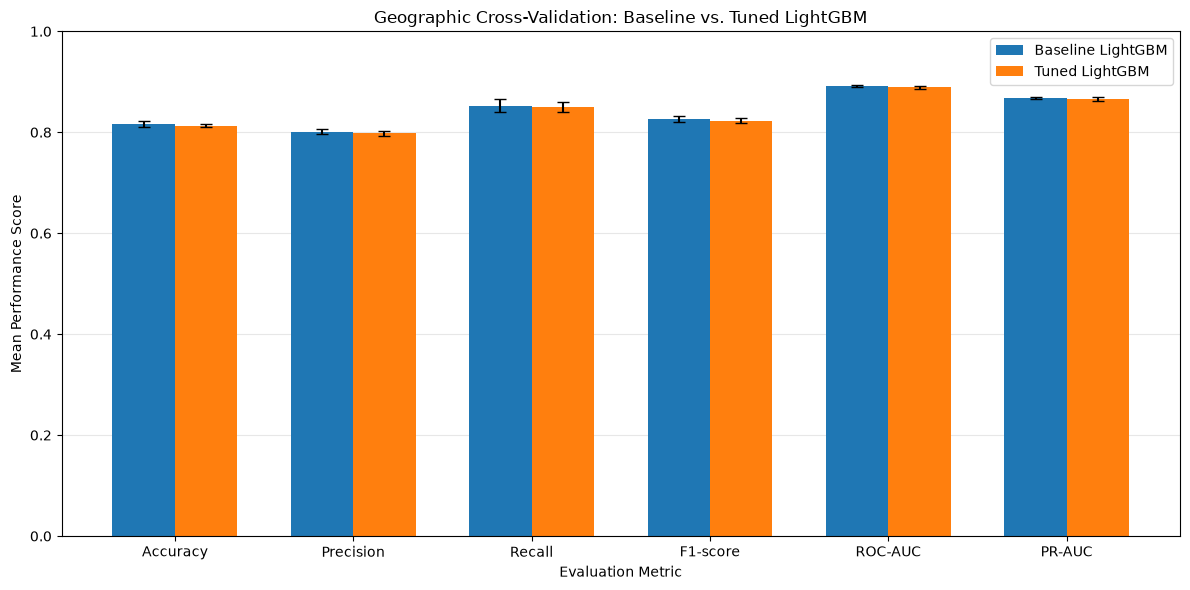

Figure saved: True


In [52]:
metric_labels = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC",
    "PR-AUC"
]

x = np.arange(len(performance_metrics))
bar_width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(
    x - bar_width / 2,
    area_comparison["baseline_mean"],
    width=bar_width,
    yerr=area_comparison["baseline_std"],
    capsize=4,
    label="Baseline LightGBM"
)

ax.bar(
    x + bar_width / 2,
    area_comparison["tuned_mean"],
    width=bar_width,
    yerr=area_comparison["tuned_std"],
    capsize=4,
    label="Tuned LightGBM"
)

ax.set_title(
    "Geographic Cross-Validation: Baseline vs. Tuned LightGBM"
)

ax.set_xlabel("Evaluation Metric")
ax.set_ylabel("Mean Performance Score")

ax.set_xticks(x)
ax.set_xticklabels(metric_labels)

ax.set_ylim(0, 1)
ax.legend()

ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

fig.savefig(
    TUNING_FIGURES_DIR / "geographic_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved:",
      (TUNING_FIGURES_DIR / "geographic_performance.png").is_file())

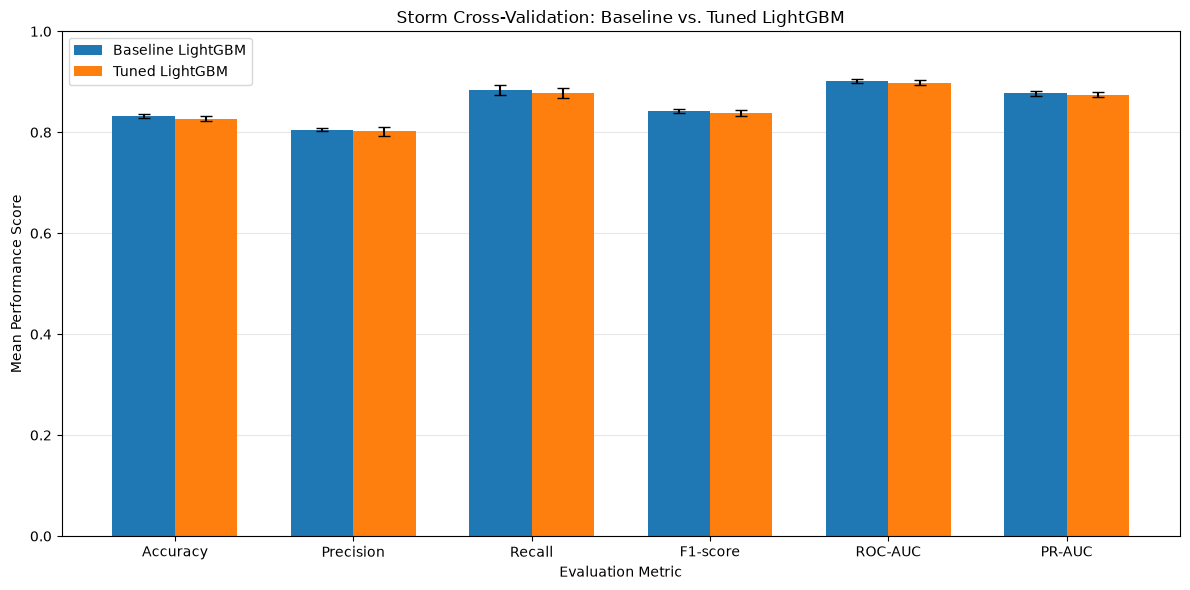

Figure saved: True


In [53]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(
    x - bar_width / 2,
    storm_comparison["baseline_mean"],
    width=bar_width,
    yerr=storm_comparison["baseline_std"],
    capsize=4,
    label="Baseline LightGBM"
)

ax.bar(
    x + bar_width / 2,
    storm_comparison["tuned_mean"],
    width=bar_width,
    yerr=storm_comparison["tuned_std"],
    capsize=4,
    label="Tuned LightGBM"
)

ax.set_title(
    "Storm Cross-Validation: Baseline vs. Tuned LightGBM"
)

ax.set_xlabel("Evaluation Metric")
ax.set_ylabel("Mean Performance Score")

ax.set_xticks(x)
ax.set_xticklabels(metric_labels)

ax.set_ylim(0, 1)
ax.legend()

ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

fig.savefig(
    TUNING_FIGURES_DIR / "storm_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved:",
      (TUNING_FIGURES_DIR / "storm_performance.png").is_file())

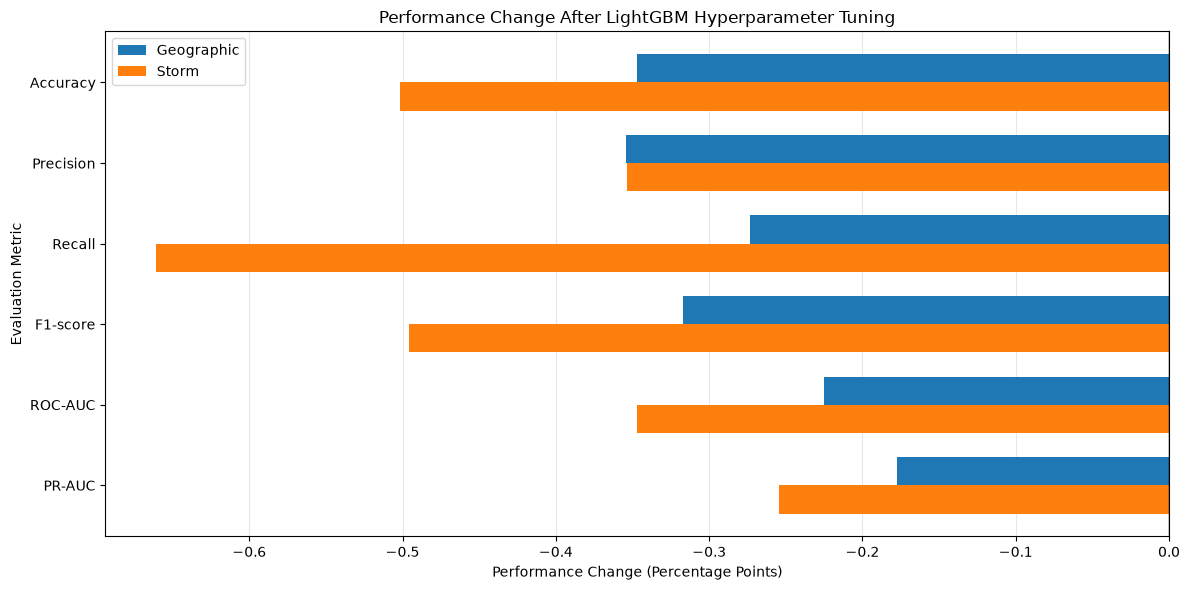

Figure saved: True


In [54]:
area_changes = overall_comparison["area_difference"] * 100
storm_changes = overall_comparison["storm_difference"] * 100

fig, ax = plt.subplots(figsize=(12, 6))

ax.barh(
    x - bar_width / 2,
    area_changes,
    height=bar_width,
    label="Geographic"
)

ax.barh(
    x + bar_width / 2,
    storm_changes,
    height=bar_width,
    label="Storm"
)

ax.set_title(
    "Performance Change After LightGBM Hyperparameter Tuning"
)

ax.set_xlabel("Performance Change (Percentage Points)")
ax.set_ylabel("Evaluation Metric")

ax.set_yticks(x)
ax.set_yticklabels(metric_labels)
ax.invert_yaxis()

ax.axvline(0, color="black", linewidth=1)

ax.legend()
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

fig.savefig(
    TUNING_FIGURES_DIR / "performance_difference.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved:",
      (TUNING_FIGURES_DIR / "performance_difference.png").is_file())

,fold,baseline,tuned,difference
0,Geographic Fold 1,0.892127,0.889305,-0.002822
1,Geographic Fold 2,0.890831,0.891178,0.000347
2,Geographic Fold 3,0.888378,0.887062,-0.001315
3,Geographic Fold 4,0.892043,0.885695,-0.006348
4,Geographic Fold 5,0.893056,0.891934,-0.001122
5,Memorial Day Flood,0.906751,0.902793,-0.003958
6,Tax Day Flood,0.898621,0.892535,-0.006087
7,Hurricane Harvey,0.899057,0.898686,-0.000372


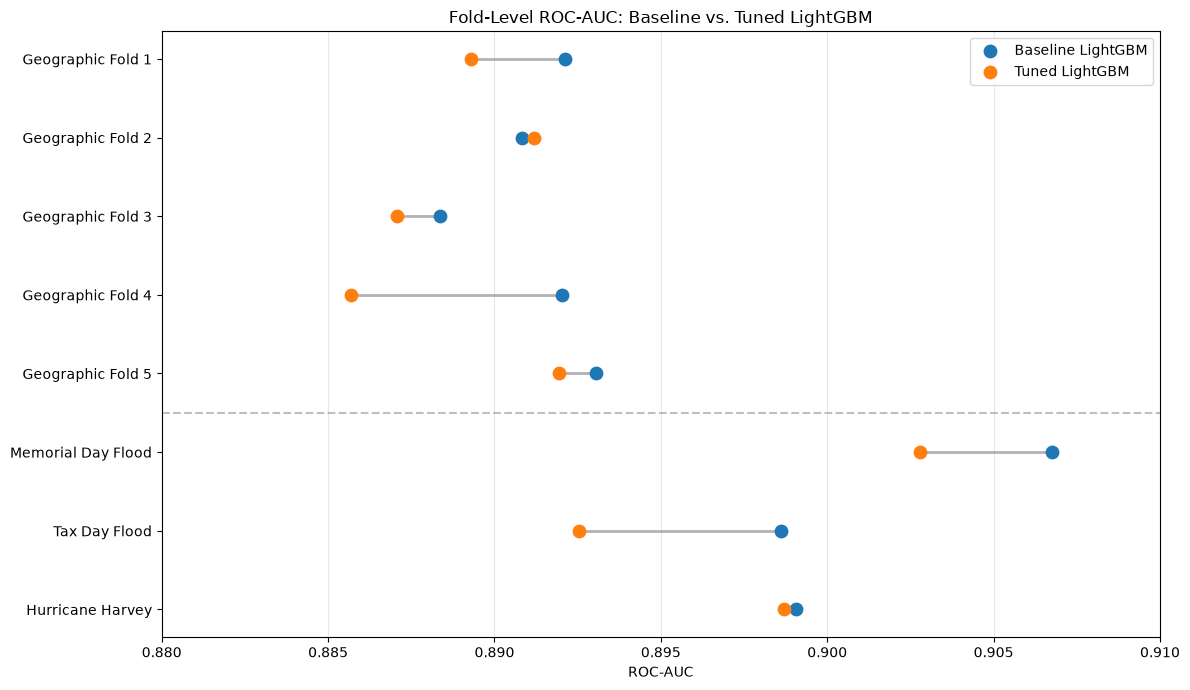

Figure saved: True
Number of improved folds: 1


In [55]:
baseline_area_folds = baseline_area_summary[
    baseline_area_summary["fold"].isin(range(1, 6))
]

baseline_storm_folds = baseline_storm_summary[
    baseline_storm_summary["fold"].isin(range(1, 4))
]

area_fold_comparison = pd.DataFrame({
    "fold": [f"Geographic Fold {i}" for i in range(1, 6)],
    "baseline": baseline_area_folds["roc_auc"].to_numpy(),
    "tuned": tuned_area_results["roc_auc"].to_numpy()
})

storm_fold_comparison = pd.DataFrame({
    "fold": tuned_storm_results["storm"].to_numpy(),
    "baseline": baseline_storm_folds["roc_auc"].to_numpy(),
    "tuned": tuned_storm_results["roc_auc"].to_numpy()
})

fold_comparison = pd.concat(
    [area_fold_comparison, storm_fold_comparison],
    ignore_index=True
)

fold_comparison["difference"] = (
    fold_comparison["tuned"] - fold_comparison["baseline"]
)

display(fold_comparison.round(6))

y_positions = np.arange(len(fold_comparison))

fig, ax = plt.subplots(figsize=(12, 7))

ax.hlines(
    y=y_positions,
    xmin=fold_comparison[["baseline", "tuned"]].min(axis=1),
    xmax=fold_comparison[["baseline", "tuned"]].max(axis=1),
    color="gray",
    alpha=0.6,
    linewidth=2
)

ax.scatter(
    fold_comparison["baseline"],
    y_positions,
    s=80,
    label="Baseline LightGBM",
    zorder=3
)

ax.scatter(
    fold_comparison["tuned"],
    y_positions,
    s=80,
    label="Tuned LightGBM",
    zorder=3
)

ax.set_yticks(y_positions)
ax.set_yticklabels(fold_comparison["fold"])
ax.invert_yaxis()

ax.axhline(4.5, color="gray", linestyle="--", alpha=0.5)

ax.set_title("Fold-Level ROC-AUC: Baseline vs. Tuned LightGBM")
ax.set_xlabel("ROC-AUC")
ax.set_xlim(0.88, 0.91)

ax.legend()
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

fig.savefig(
    TUNING_FIGURES_DIR / "fold_roc_auc_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved:",
      (TUNING_FIGURES_DIR / "fold_roc_auc_comparison.png").is_file())

print("Number of improved folds:",
      (fold_comparison["difference"] > 0).sum())

## Experimental Conclusions and Model Recommendation

### Objective

The objective of this experiment was to determine whether hyperparameter optimization could improve the performance of the existing LightGBM model for urban flood hotspot prediction.

### Methodology

Randomized hyperparameter search was performed using nested cross-validation. Twenty candidate configurations were sampled from a search space containing 2,916 possible combinations across seven hyperparameters. ROC-AUC was used as the primary optimization metric.

The experiment maintained the original five geographic validation folds, three leave-one-storm-out validation folds, feature selection, and preprocessing procedures. Hyperparameter selection was performed exclusively within the training portion of each outer fold.

A total of 528 model fits, including refitting, were completed in approximately 11.87 minutes.

### Results

The tuned models did not improve average performance under either validation strategy.

- Geographic mean ROC-AUC decreased from 0.891287 to 0.889035.
- Storm-based mean ROC-AUC decreased from 0.901477 to 0.898005.
- Geographic mean recall decreased from 0.852761 to 0.850028.
- Storm-based mean recall decreased from 0.884294 to 0.877686.
- Only one of the eight outer validation folds demonstrated improved ROC-AUC.
- None of the six average evaluation metrics improved under either validation strategy.

The most frequently selected hyperparameter configuration contained 500 estimators, a learning rate of 0.1, 15 leaves, a maximum depth of 5, a minimum of 50 samples per leaf, and L2 regularization of 1. This configuration was selected in five of the eight outer folds.

Although the searches frequently selected more restricted tree structures and stronger regularization, these selections did not improve average outer validation performance.

### Recommendation

Retain the original LightGBM configuration for the FloodSense application. The original model demonstrated stronger average performance across both validation strategies.

No modifications to the original model configuration or frozen final evaluation setup are recommended based on this experiment.

### Limitations

- Only 20 of the 2,916 possible hyperparameter combinations were sampled per outer fold.
- The original baseline configuration was not explicitly guaranteed inclusion among the randomly sampled candidates.
- Only three historical storms were available for storm-based cross-validation.
- The storm-based validation strategy permits geographic overlap between training and validation locations.
- The observed performance differences have not been established as statistically significant.
- The tuned models were not evaluated on the reserved Imelda test dataset.

These findings do not establish that the original hyperparameters are globally optimal. They demonstrate that the randomized hyperparameter optimization procedure investigated in this experiment did not improve average validation performance.

In [47]:
performance_exports = {
    "baseline_area_results.csv": (baseline_area_summary, False),
    "baseline_storm_results.csv": (baseline_storm_summary, False),
    "tuned_area_results.csv": (tuned_area_results, False),
    "tuned_storm_results.csv": (tuned_storm_results, False),
    "tuned_area_summary.csv": (tuned_area_summary, True),
    "tuned_storm_summary.csv": (tuned_storm_summary, True),
    "area_comparison.csv": (area_comparison, True),
    "storm_comparison.csv": (storm_comparison, True),
    "overall_comparison.csv": (overall_comparison, True),
    "fold_comparison.csv": (fold_comparison, False)
}

for filename, (dataframe, include_index) in performance_exports.items():
    output_path = TUNING_OUTPUT_DIR / filename

    dataframe.to_csv(
        output_path,
        index=include_index
    )

    print(f"{filename}: Saved = {output_path.is_file()}")

print("\nTotal performance files saved:",
      sum(
          (TUNING_OUTPUT_DIR / filename).is_file()
          for filename in performance_exports
      ))

baseline_area_results.csv: Saved = True
baseline_storm_results.csv: Saved = True
tuned_area_results.csv: Saved = True
tuned_storm_results.csv: Saved = True
tuned_area_summary.csv: Saved = True
tuned_storm_summary.csv: Saved = True
area_comparison.csv: Saved = True
storm_comparison.csv: Saved = True
overall_comparison.csv: Saved = True
fold_comparison.csv: Saved = True

Total performance files saved: 10


In [48]:
parameter_exports = {
    "selected_area_params.csv": area_params_df,
    "selected_storm_params.csv": storm_params_df,
    "all_selected_params.csv": all_selected_params,
    "configuration_frequency.csv": configuration_frequency
}

for filename, dataframe in parameter_exports.items():
    output_path = TUNING_OUTPUT_DIR / filename

    dataframe.to_csv(output_path, index=False)

    print(f"{filename}: Saved = {output_path.is_file()}")

print("\nTotal hyperparameter files saved:",
      sum(
          (TUNING_OUTPUT_DIR / filename).is_file()
          for filename in parameter_exports
      ))

selected_area_params.csv: Saved = True
selected_storm_params.csv: Saved = True
all_selected_params.csv: Saved = True
configuration_frequency.csv: Saved = True

Total hyperparameter files saved: 4


In [49]:
tuned_area_oof = pd.concat(
    tuned_area_oof_records,
    ignore_index=True
).sort_values("row_index").reset_index(drop=True)

tuned_storm_oof = pd.concat(
    tuned_storm_oof_records,
    ignore_index=True
).sort_values("row_index").reset_index(drop=True)

print("Original dataset rows:", len(df))

print("\nGeographic OOF shape:", tuned_area_oof.shape)
print("Geographic OOF columns:",
      tuned_area_oof.columns.tolist())

display(tuned_area_oof.head())

print("\nStorm OOF shape:", tuned_storm_oof.shape)
print("Storm OOF columns:",
      tuned_storm_oof.columns.tolist())

display(tuned_storm_oof.head())

Original dataset rows: 66514

Geographic OOF shape: (66514, 4)
Geographic OOF columns: ['row_index', 'y_true', 'y_prob', 'fold']


,row_index,y_true,y_prob,fold
0,0,1,0.609471,3
1,1,1,0.565844,5
2,2,1,0.449233,2
3,3,1,0.363458,1
4,4,1,0.868209,3



Storm OOF shape: (66514, 5)
Storm OOF columns: ['row_index', 'y_true', 'y_prob', 'fold', 'storm']


,row_index,y_true,y_prob,fold,storm
0,0,1,0.603312,1,Memorial Day Flood
1,1,1,0.615935,1,Memorial Day Flood
2,2,1,0.437435,1,Memorial Day Flood
3,3,1,0.417128,1,Memorial Day Flood
4,4,1,0.889079,1,Memorial Day Flood


In [50]:
def validate_oof_predictions(oof_df, strategy):

    checks = {
        "Correct row count": len(oof_df) == len(df),

        "No duplicate row indexes":
            oof_df["row_index"].is_unique,

        "Complete row index coverage":
            np.array_equal(
                oof_df["row_index"].to_numpy(),
                np.arange(len(df))
            ),

        "No missing values":
            not oof_df.isna().any().any(),

        "Valid probabilities":
            oof_df["y_prob"].between(0, 1).all(),

        "Correct target labels":
            np.array_equal(
                oof_df["y_true"].to_numpy(),
                df[TARGET].to_numpy()
            )
    }

    expected_folds = np.zeros(len(df), dtype=int)

    if strategy == "Geographic":

        for fold_number, (_, val_idx) in enumerate(
            area_splits, start=1
        ):
            expected_folds[val_idx] = fold_number

    elif strategy == "Storm":

        for fold_number, (_, _, val_idx) in enumerate(
            storm_splits, start=1
        ):
            expected_folds[val_idx] = fold_number

        checks["Correct storm names"] = np.array_equal(
            oof_df["storm"].to_numpy(),
            df["storm_name"].to_numpy()
        )

    checks["Correct fold assignments"] = np.array_equal(
        oof_df["fold"].to_numpy(),
        expected_folds
    )

    print(f"\n{strategy} OOF validation:")

    for check_name, passed in checks.items():
        print(f"{check_name}: {passed}")

    print("All checks passed:", all(checks.values()))

    return all(checks.values())


area_oof_valid = validate_oof_predictions(
    tuned_area_oof, "Geographic"
)

storm_oof_valid = validate_oof_predictions(
    tuned_storm_oof, "Storm"
)


Geographic OOF validation:
Correct row count: True
No duplicate row indexes: True
Complete row index coverage: True
No missing values: True
Valid probabilities: True
Correct target labels: True
Correct fold assignments: True
All checks passed: True

Storm OOF validation:
Correct row count: True
No duplicate row indexes: True
Complete row index coverage: True
No missing values: True
Valid probabilities: True
Correct target labels: True
Correct storm names: True
Correct fold assignments: True
All checks passed: True


In [51]:
assert area_oof_valid, "Geographic OOF validation failed."
assert storm_oof_valid, "Storm OOF validation failed."

prediction_exports = {
    "tuned_area_oof.csv": tuned_area_oof,
    "tuned_storm_oof.csv": tuned_storm_oof
}

for filename, dataframe in prediction_exports.items():
    output_path = TUNING_OUTPUT_DIR / filename

    dataframe.to_csv(output_path, index=False)

    print(f"\n{filename}")
    print("Saved:", output_path.is_file())
    print("Rows:", len(dataframe))
    print("File size (MB):",
          round(output_path.stat().st_size / (1024 ** 2), 2))

print("\nTotal prediction files saved:",
      sum(
          (TUNING_OUTPUT_DIR / filename).is_file()
          for filename in prediction_exports
      ))


tuned_area_oof.csv
Saved: True
Rows: 66514
File size (MB): 1.92

tuned_storm_oof.csv
Saved: True
Rows: 66514
File size (MB): 2.98

Total prediction files saved: 2
